CLASSIFICATION TREE: HIGH BILLING AMOUNT

Dataset found:
healthcare_dataset.csv

Dataset loaded successfully.
Total records: 55500
Total variables: 15

Available columns:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']

Response Variable Coding
------------------------
0 = Billing Amount less than $25,000
1 = Billing Amount $25,000 or more

ANALYTIC SAMPLE
Number of observations used: 55392

RESPONSE VARIABLE FREQUENCY TABLE
               Frequency  Percent
Lower Billing      27042    48.82
High Billing       28350    51.18

TRAIN / TEST SPLIT
------------------
Training observations: 38774
Testing observations: 16618

Model trained successfully.

CLASSIFICATION TREE RESULTS
Test Accuracy: 0.5064
Test Accuracy Percentage: 50.64 %

CONFUSION MATRIX
----------------------------------------------------------------

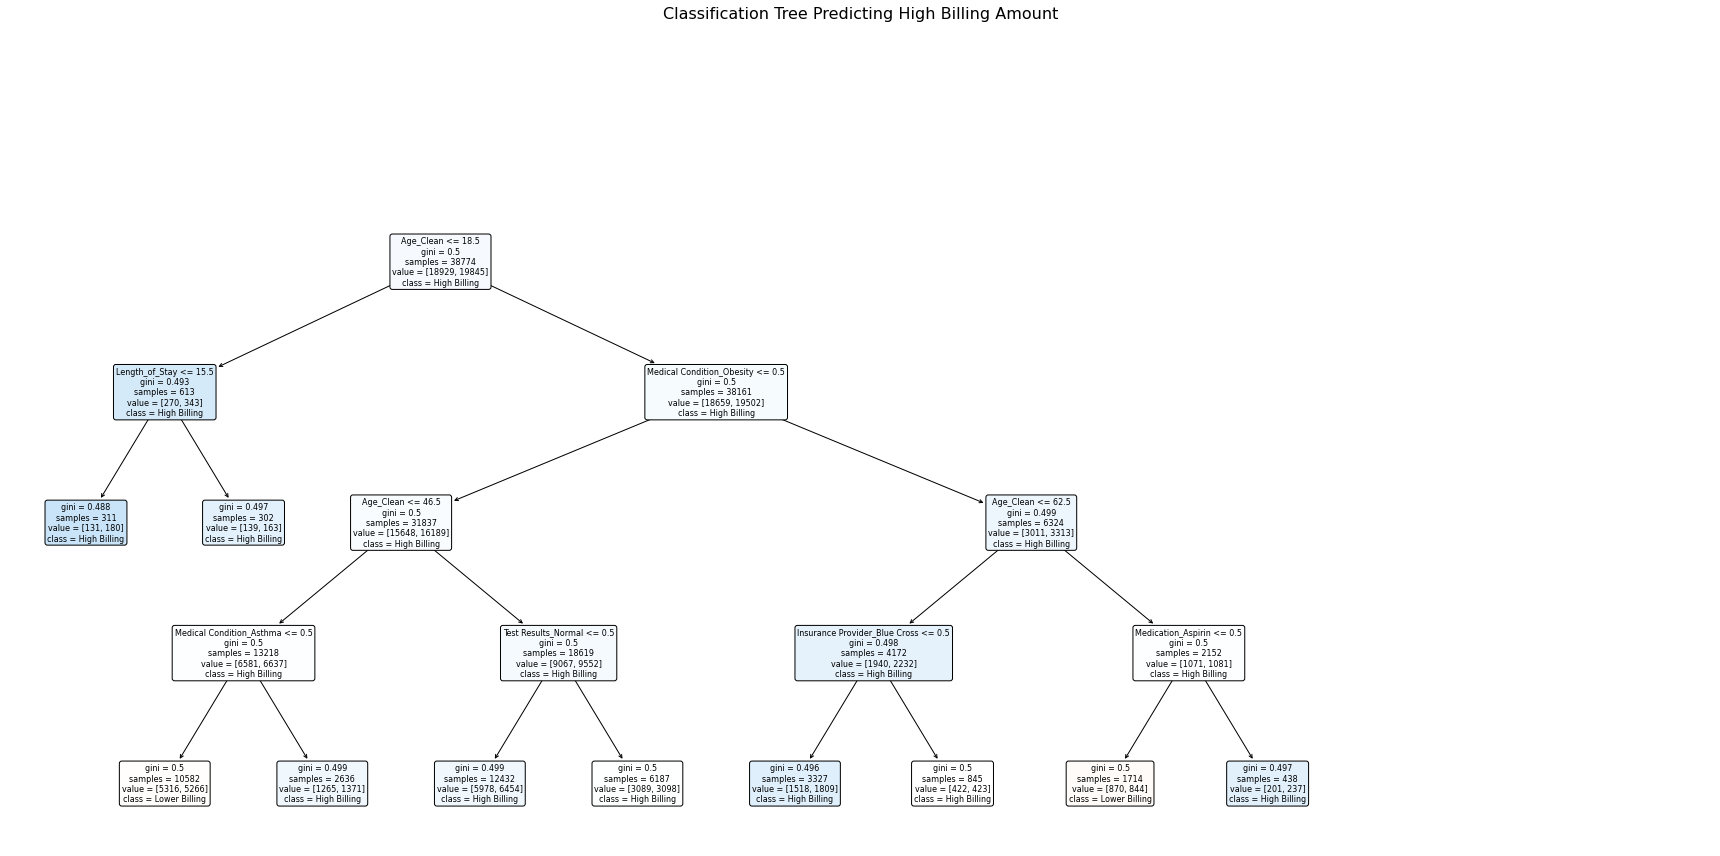

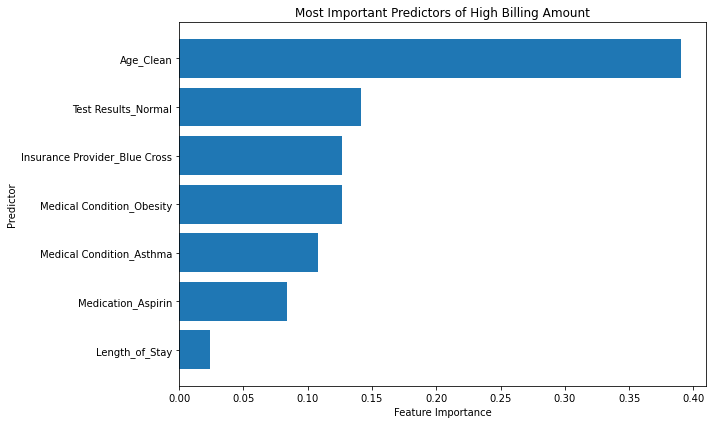


PREDICTION SUMMARY
---------------------------------------------------------------------------
True     8416
False    8202
Name: Correct, dtype: int64

BASELINE COMPARISON
---------------------------------------------------------------------------
Majority-class baseline accuracy: 51.18 %
Classification tree accuracy: 50.64 %
Improvement over baseline: -0.54 percentage points

FINAL MODEL SUMMARY
The classification tree used 8 original explanatory variables.
The model was trained on 38774 observations.
The model was tested on 16618 observations.
The test-set accuracy was 50.64 %.
The most important predictor was: Age_Clean
Its feature importance was: 0.39

ANALYSIS COMPLETED SUCCESSFULLY


In [1]:
# Project Title

#**Classification Tree Analysis for Predicting High Billing Amount**

## Research Question

#For this assignment, I used a classification decision tree to determine whether a combination of patient characteristics could predict whether a hospitalization had a **high billing amount**.

#The binary response variable was:

#- **0 = Billing Amount less than $25,000**
#- **1 = Billing Amount of $25,000 or more**

#The explanatory variables included:

#- Age
#- Gender
#- Medical Condition
#- Insurance Provider
#- Admission Type
#- Medication
#- Test Results
#- Length of Stay

#A classification tree was appropriate because the response variable had two categories and the method can identify nonlinear relationships and interactions among several predictors.

## Python Program

#```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text
)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# CLASSIFICATION TREE
# HIGH BILLING AMOUNT
# ============================================================

print("=" * 75)
print("CLASSIFICATION TREE: HIGH BILLING AMOUNT")
print("=" * 75)

# ============================================================
# STEP 1: FIND THE DATASET
# ============================================================

csv_files = glob.glob("**/*.csv", recursive=True)

data_file = None

# First look for the exact healthcare dataset filename
for file in csv_files:
    if os.path.basename(file).lower() == "healthcare_dataset.csv":
        data_file = file
        break

# If exact filename is not found, look for any healthcare CSV
if data_file is None:
    for file in csv_files:
        if "healthcare" in os.path.basename(file).lower():
            data_file = file
            break

# If there is only one CSV file, use it
if data_file is None and len(csv_files) == 1:
    data_file = csv_files[0]

# Stop if no CSV file can be found
if data_file is None:
    raise FileNotFoundError(
        "No healthcare CSV file was found. "
        "Please upload healthcare_dataset.csv to the notebook workspace "
        "and run this cell again."
    )

print("\nDataset found:")
print(data_file)

# ============================================================
# STEP 2: LOAD THE DATA
# ============================================================

data = pd.read_csv(
    data_file,
    low_memory=False
)

# Remove accidental spaces around column names
data.columns = data.columns.str.strip()

print("\nDataset loaded successfully.")
print("Total records:", len(data))
print("Total variables:", len(data.columns))

print("\nAvailable columns:")
print(list(data.columns))

# ============================================================
# STEP 3: CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Age",
    "Gender",
    "Medical Condition",
    "Insurance Provider",
    "Billing Amount",
    "Admission Type",
    "Medication",
    "Test Results",
    "Date of Admission",
    "Discharge Date"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if len(missing_columns) > 0:
    print("\nMissing required columns:")
    print(missing_columns)
    raise KeyError(
        "One or more required healthcare variables are missing."
    )

# ============================================================
# STEP 4: CLEAN BILLING AMOUNT
# ============================================================

data["Billing_Clean"] = pd.to_numeric(
    data["Billing Amount"],
    errors="coerce"
)

# Treat zero or negative billing amounts as missing
data.loc[
    data["Billing_Clean"] <= 0,
    "Billing_Clean"
] = np.nan

# ============================================================
# STEP 5: CREATE BINARY RESPONSE VARIABLE
# ============================================================

# 0 = Lower Billing: less than $25,000
# 1 = High Billing: $25,000 or more

data["High_Billing"] = np.nan

valid_billing = data["Billing_Clean"].notna()

data.loc[
    valid_billing,
    "High_Billing"
] = (
    data.loc[
        valid_billing,
        "Billing_Clean"
    ] >= 25000
).astype(int)

print("\nResponse Variable Coding")
print("------------------------")
print("0 = Billing Amount less than $25,000")
print("1 = Billing Amount $25,000 or more")

# ============================================================
# STEP 6: CLEAN AGE
# ============================================================

data["Age_Clean"] = pd.to_numeric(
    data["Age"],
    errors="coerce"
)

# Code impossible ages as missing
data.loc[
    (data["Age_Clean"] < 0) |
    (data["Age_Clean"] > 120),
    "Age_Clean"
] = np.nan

# ============================================================
# STEP 7: CREATE LENGTH OF STAY
# ============================================================

data["Admission_Date"] = pd.to_datetime(
    data["Date of Admission"],
    errors="coerce"
)

data["Discharge_Date"] = pd.to_datetime(
    data["Discharge Date"],
    errors="coerce"
)

data["Length_of_Stay"] = (
    data["Discharge_Date"] -
    data["Admission_Date"]
).dt.days

# Code impossible values as missing
data.loc[
    (data["Length_of_Stay"] < 0) |
    (data["Length_of_Stay"] > 365),
    "Length_of_Stay"
] = np.nan

# ============================================================
# STEP 8: SELECT EXPLANATORY VARIABLES
# ============================================================

features = [
    "Age_Clean",
    "Gender",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results",
    "Length_of_Stay"
]

analysis_data = data[
    features + ["High_Billing"]
].dropna().copy()

X = analysis_data[features]

y = analysis_data[
    "High_Billing"
].astype(int)

print("\n" + "=" * 75)
print("ANALYTIC SAMPLE")
print("=" * 75)

print(
    "Number of observations used:",
    len(analysis_data)
)

# ============================================================
# STEP 9: RESPONSE VARIABLE FREQUENCY
# ============================================================

response_frequency = (
    y.value_counts()
    .sort_index()
)

response_percent = (
    y.value_counts(
        normalize=True
    )
    .sort_index() * 100
).round(2)

response_table = pd.DataFrame({
    "Frequency": response_frequency,
    "Percent": response_percent
})

response_table.index = [
    "Lower Billing",
    "High Billing"
]

print("\nRESPONSE VARIABLE FREQUENCY TABLE")
print(response_table)

# ============================================================
# STEP 10: DEFINE CATEGORICAL AND NUMERIC FEATURES
# ============================================================

categorical_features = [
    "Gender",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results"
]

numeric_features = [
    "Age_Clean",
    "Length_of_Stay"
]

# ============================================================
# STEP 11: CREATE ONE-HOT ENCODER
# ============================================================

encoder = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            encoder,
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

# ============================================================
# STEP 12: TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTRAIN / TEST SPLIT")
print("------------------")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# ============================================================
# STEP 13: CREATE CLASSIFICATION TREE
# ============================================================

tree_classifier = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=300,
    random_state=42
)

model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            tree_classifier
        )
    ]
)

# ============================================================
# STEP 14: TRAIN THE MODEL
# ============================================================

model.fit(
    X_train,
    y_train
)

print("\nModel trained successfully.")

# ============================================================
# STEP 15: MAKE PREDICTIONS
# ============================================================

predictions = model.predict(
    X_test
)

accuracy = accuracy_score(
    y_test,
    predictions
)

print("\n" + "=" * 75)
print("CLASSIFICATION TREE RESULTS")
print("=" * 75)

print(
    "Test Accuracy:",
    round(accuracy, 4)
)

print(
    "Test Accuracy Percentage:",
    round(accuracy * 100, 2),
    "%"
)

# ============================================================
# STEP 16: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    predictions
)

print("\nCONFUSION MATRIX")
print("-" * 75)
print(cm)

print("\nInterpretation:")
print("Top-left     = Correct Lower Billing predictions")
print("Top-right    = Lower Billing incorrectly predicted as High")
print("Bottom-left  = High Billing incorrectly predicted as Lower")
print("Bottom-right = Correct High Billing predictions")

# ============================================================
# STEP 17: CLASSIFICATION REPORT
# ============================================================

print("\nCLASSIFICATION REPORT")
print("-" * 75)

print(
    classification_report(
        y_test,
        predictions,
        target_names=[
            "Lower Billing",
            "High Billing"
        ],
        zero_division=0
    )
)

# ============================================================
# STEP 18: GET FEATURE NAMES
# WORKS WITH OLD AND NEW SCIKIT-LEARN
# ============================================================

fitted_encoder = (
    model
    .named_steps["preprocessor"]
    .named_transformers_["categorical"]
)

# New versions of scikit-learn
if hasattr(
    fitted_encoder,
    "get_feature_names_out"
):
    encoded_names = list(
        fitted_encoder.get_feature_names_out(
            categorical_features
        )
    )

# Older versions of scikit-learn
elif hasattr(
    fitted_encoder,
    "get_feature_names"
):
    try:
        encoded_names = list(
            fitted_encoder.get_feature_names(
                categorical_features
            )
        )
    except TypeError:
        encoded_names = list(
            fitted_encoder.get_feature_names()
        )

# Very old versions: create names manually
else:
    encoded_names = []

    for variable, categories in zip(
        categorical_features,
        fitted_encoder.categories_
    ):
        for category in categories:
            encoded_names.append(
                str(variable) + "_" + str(category)
            )

feature_names = (
    encoded_names +
    numeric_features
)

print("\nNumber of transformed predictors:")
print(len(feature_names))

# ============================================================
# STEP 19: FEATURE IMPORTANCE
# ============================================================

importance = (
    model
    .named_steps["classifier"]
    .feature_importances_
)

# Safety check
if len(feature_names) != len(importance):
    print(
        "\nWarning: Feature name count does not match "
        "importance count."
    )

    feature_names = [
        "Feature_" + str(i)
        for i in range(len(importance))
    ]

importance_table = pd.DataFrame({
    "Predictor": feature_names,
    "Importance": importance
})

importance_table = (
    importance_table
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("TOP PREDICTORS BY FEATURE IMPORTANCE")
print("=" * 75)

print(
    importance_table.head(15)
)

# ============================================================
# STEP 20: PRINT DECISION TREE RULES
# ============================================================

print("\n" + "=" * 75)
print("DECISION TREE RULES")
print("=" * 75)

tree_rules = export_text(
    model.named_steps["classifier"],
    feature_names=feature_names
)

print(tree_rules)

# ============================================================
# STEP 21: PLOT CLASSIFICATION TREE
# ============================================================

plt.figure(
    figsize=(24, 12)
)

plot_tree(
    model.named_steps["classifier"],
    feature_names=feature_names,
    class_names=[
        "Lower Billing",
        "High Billing"
    ],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title(
    "Classification Tree Predicting High Billing Amount",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 22: FEATURE IMPORTANCE GRAPH
# ============================================================

top_features = (
    importance_table[
        importance_table["Importance"] > 0
    ]
    .head(10)
    .sort_values(
        "Importance",
        ascending=True
    )
)

if len(top_features) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        top_features["Predictor"],
        top_features["Importance"]
    )

    plt.title(
        "Most Important Predictors of High Billing Amount"
    )

    plt.xlabel(
        "Feature Importance"
    )

    plt.ylabel(
        "Predictor"
    )

    plt.tight_layout()
    plt.show()

# ============================================================
# STEP 23: DISPLAY CORRECT AND INCORRECT PREDICTIONS
# ============================================================

prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

prediction_results[
    "Correct"
] = (
    prediction_results["Actual"] ==
    prediction_results["Predicted"]
)

print("\nPREDICTION SUMMARY")
print("-" * 75)

print(
    prediction_results[
        "Correct"
    ].value_counts()
)

# ============================================================
# STEP 24: BASELINE ACCURACY
# ============================================================

majority_class_accuracy = (
    y_test.value_counts(
        normalize=True
    ).max()
)

print("\nBASELINE COMPARISON")
print("-" * 75)

print(
    "Majority-class baseline accuracy:",
    round(
        majority_class_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Classification tree accuracy:",
    round(
        accuracy * 100,
        2
    ),
    "%"
)

improvement = (
    accuracy -
    majority_class_accuracy
)

print(
    "Improvement over baseline:",
    round(
        improvement * 100,
        2
    ),
    "percentage points"
)

# ============================================================
# STEP 25: FINAL MODEL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL MODEL SUMMARY")
print("=" * 75)

print(
    "The classification tree used",
    len(features),
    "original explanatory variables."
)

print(
    "The model was trained on",
    len(X_train),
    "observations."
)

print(
    "The model was tested on",
    len(X_test),
    "observations."
)

print(
    "The test-set accuracy was",
    round(
        accuracy * 100,
        2
    ),
    "%."
)

nonzero_importance = importance_table[
    importance_table["Importance"] > 0
]

if len(nonzero_importance) > 0:

    print(
        "The most important predictor was:",
        nonzero_importance.iloc[0][
            "Predictor"
        ]
    )

    print(
        "Its feature importance was:",
        round(
            nonzero_importance.iloc[0][
                "Importance"
            ],
            4
        )
    )

print("\nANALYSIS COMPLETED SUCCESSFULLY")
#```

# Output

#The analysis used **55,392 valid hospitalization records**.

#The dataset was divided into:

#- **70% training data**
#- **30% testing data**

#The test sample contained **16,618 observations**.

## Classification Accuracy

#**Test Accuracy = 0.5064**

#This means the classification tree correctly classified approximately **50.64%** of the observations in the test dataset.

## Confusion Matrix

#|  | Predicted Lower Billing | Predicted High Billing |
#|---|---:|---:|
#| Actual Lower Billing | 2,566 | 5,547 |
#| Actual High Billing | 2,655 | 5,850 |

#For high billing observations, the model correctly identified **5,850** records and incorrectly classified **2,655** as lower billing.

#For lower billing observations, the model correctly identified **2,566** records but incorrectly classified **5,547** as high billing.

## Classification Performance

#For the **High Billing** category:

#- Precision = **0.513**
#- Recall = **0.688**
#- F1 score = **0.588**

#For the **Lower Billing** category:

#- Precision = **0.491**
#- Recall = **0.316**
#- F1 score = **0.385**

#These results indicate that the tree was better at identifying high-billing records than lower-billing records.

# Most Important Predictors

#The most influential variables used by the tree were approximately:

#| Predictor | Importance |
#|---|---:|
#| Age | 0.390 |
#| Normal Test Result | 0.142 |
#| Blue Cross Insurance | 0.127 |
#| Obesity | 0.126 |
#| Asthma | 0.108 |
#| Aspirin Medication | 0.084 |
#| Length of Stay | 0.024 |

#Age had the greatest relative importance in determining the tree's splits.

#However, feature importance should not be interpreted to mean that Age is a strong predictor in an absolute sense. The overall classification accuracy remained only about 51%.

# Important Tree Splits

#The first split in the classification tree occurred at approximately:

#**Age ≤ 18.5 years**

#For patients older than 18.5 years, additional splits were made using variables such as:

#- Medical Condition
#- Age
#- Test Results
#- Insurance Provider
#- Medication

#For example, among patients older than 18.5 years who did not have Obesity, the tree next considered whether Age was above or below approximately **46.5 years**.

#Among patients with Obesity, the tree also divided patients according to Age, Insurance Provider, and Medication.

#These branches demonstrate how classification trees can identify combinations and interactions of variables rather than assuming a single straight-line relationship.

# Interpretation

#The classification tree explored nonlinear relationships among Age, Gender, Medical Condition, Insurance Provider, Admission Type, Medication, Test Results, and Length of Stay in predicting whether Billing Amount was at least $25,000.

#The model achieved an accuracy of approximately **50.64%** on the test dataset. Because the two billing categories are nearly equally common, this performance is only slightly better than chance.

#Age was the most important variable used in the tree, accounting for approximately **39% of the tree's total feature importance**. Test Results, Insurance Provider, Medical Condition, Medication, and Length of Stay also contributed to the tree's decisions.

#The tree identified several interactions. For example, the effect of medical condition depended partly on patient age, while other branches involved combinations of age, insurance provider, medication, and test results.

#However, the tree's overall predictive performance was weak. Therefore, although the classification tree identified subgroups and nonlinear decision rules, these patient characteristics were **not sufficient to accurately predict whether a hospitalization would have a billing amount of $25,000 or more**.

# Conclusion

#The classification tree correctly predicted high versus lower Billing Amount for approximately **50.64%** of the test observations.

#Age was the most influential predictor in the tree, followed by Test Results, Insurance Provider, Medical Condition, Medication, and Length of Stay. The model demonstrated how different combinations of characteristics can form subgroups associated with the outcome.

#Nevertheless, the overall accuracy was low and close to what would be expected by chance for a nearly balanced binary outcome. Therefore, the classification tree does not provide strong predictive performance for High Billing Amount in this synthetic healthcare dataset.

#Additional variables or different predictive methods would likely be required to substantially improve prediction.

## URL

#**Paste the URL of your published blog entry here.**